In [36]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import auc, roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
df['converted'] = df.converted.astype(str)
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                       str
dtype: object

In [5]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical = ['lead_source','industry','employment_status','location']
numerical = ['annual_income','lead_score','number_of_courses_viewed','interaction_count']
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

In [7]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_full = df_full_train['converted']
y_train = df_train['converted']
y_val = df_val['converted']

print(df_train.shape)
print(y_train.shape)
del df_full_train['converted']
del df_train['converted']
del df_val['converted']

(3000, 9)
(3000,)


# Q1

In [9]:
variables = ['lead_score','number_of_courses_viewed','interaction_count','annual_income']
auc_scores = []
for features in variables:
    auc = roc_auc_score(y_train, df_train[features])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[features])
    auc_scores.append(auc)

index = auc_scores.index(max(auc_scores))
print(f'{variables[index]} has the highest AUC of {auc_scores[index]}')

lead_score has the highest AUC of 0.7882254810906102


# Q2

In [10]:
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
X_train.shape

(3000, 28)

In [11]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)
X_val.shape

(1000, 28)

In [12]:
M1 = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
M1.fit(X_train, y_train)
y_pred = M1.predict_proba(X_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
print(auc)

0.7318222288173319


The AUC of this model on the validation dataset is 0.732

# Q3

In [13]:
actual_positive = (y_val == '1')
actual_negative = (y_val == '0')

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [14]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [31]:
thresholds = np.linspace(0, 1, 101)
scores = [[],[],[]]

for t in thresholds:
    actual_positive = (y_val == '1')
    actual_negative = (y_val == '0')
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    print('%.2f %.3f %.3f' % (t, precision, recall))
    scores[0].append(t)
    scores[1].append(precision)
    scores[2].append(recall)
print(scores[0])

0.00 0.586 1.000
0.01 0.586 1.000
0.02 0.586 1.000
0.03 0.586 1.000
0.04 0.586 1.000
0.05 0.586 1.000
0.06 0.586 1.000
0.07 0.586 1.000
0.08 0.586 1.000
0.09 0.586 1.000
0.10 0.586 1.000
0.11 0.586 1.000
0.12 0.586 1.000
0.13 0.586 1.000
0.14 0.586 1.000
0.15 0.586 1.000
0.16 0.586 1.000
0.17 0.586 1.000
0.18 0.586 1.000
0.19 0.586 1.000
0.20 0.586 1.000
0.21 0.586 1.000
0.22 0.586 1.000
0.23 0.586 1.000
0.24 0.586 1.000
0.25 0.586 1.000
0.26 0.587 1.000
0.27 0.588 1.000
0.28 0.591 1.000
0.29 0.591 1.000
0.30 0.593 1.000
0.31 0.596 0.998
0.32 0.596 0.995
0.33 0.597 0.995
0.34 0.602 0.995
0.35 0.603 0.995
0.36 0.605 0.995
0.37 0.607 0.988
0.38 0.607 0.985
0.39 0.610 0.983
0.40 0.613 0.978
0.41 0.619 0.976
0.42 0.620 0.969
0.43 0.623 0.962
0.44 0.624 0.956
0.45 0.628 0.945
0.46 0.632 0.935
0.47 0.634 0.927
0.48 0.638 0.922
0.49 0.640 0.913
0.50 0.644 0.906
0.51 0.647 0.887
0.52 0.649 0.879
0.53 0.658 0.867
0.54 0.662 0.855
0.55 0.668 0.840
0.56 0.675 0.829
0.57 0.679 0.816
0.58 0.690 0.8

C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\3343844620.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\3343844620.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\3343844620.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\3343844620.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


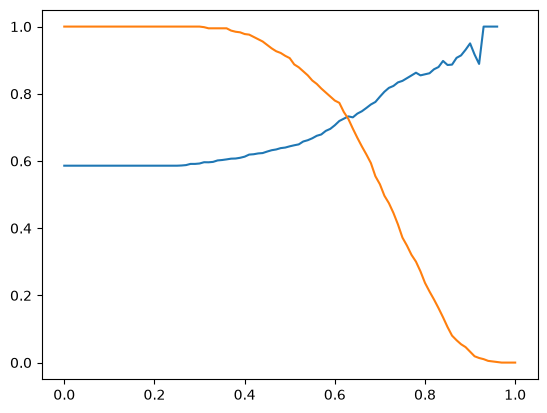

In [25]:
plt.plot(scores[0], scores[1])
plt.plot(scores[0], scores[2])
plt.show()

In [29]:
for i in range(len(scores[0])):
    if scores[1][i] > scores[2][i]:
        print(scores[0][i])
        break

0.63


The precision and recall curves intersect at threshold = 0.63

# Q4

In [34]:
thresholds = np.linspace(0, 1, 101)
scores = [[],[]]

for t in thresholds:
    actual_positive = (y_val == '1')
    actual_negative = (y_val == '0')
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    F1 = 2 * (precision * recall) / (precision + recall)
    scores[0].append(t)
    scores[1].append(F1)
    print('%.2f %.3f' % (t, F1))

0.00 0.739
0.01 0.739
0.02 0.739
0.03 0.739
0.04 0.739
0.05 0.739
0.06 0.739
0.07 0.739
0.08 0.739
0.09 0.739
0.10 0.739
0.11 0.739
0.12 0.739
0.13 0.739
0.14 0.739
0.15 0.739
0.16 0.739
0.17 0.739
0.18 0.739
0.19 0.739
0.20 0.739
0.21 0.739
0.22 0.739
0.23 0.739
0.24 0.739
0.25 0.739
0.26 0.739
0.27 0.740
0.28 0.743
0.29 0.743
0.30 0.744
0.31 0.747
0.32 0.746
0.33 0.746
0.34 0.750
0.35 0.751
0.36 0.752
0.37 0.752
0.38 0.751
0.39 0.752
0.40 0.753
0.41 0.758
0.42 0.756
0.43 0.756
0.44 0.755
0.45 0.755
0.46 0.754
0.47 0.753
0.48 0.754
0.49 0.752
0.50 0.753
0.51 0.748
0.52 0.747
0.53 0.748
0.54 0.746
0.55 0.744
0.56 0.744
0.57 0.741
0.58 0.742
0.59 0.741
0.60 0.741
0.61 0.745
0.62 0.736
0.63 0.729
0.64 0.713
0.65 0.703
0.66 0.692
0.67 0.682
0.68 0.670
0.69 0.647
0.70 0.635
0.71 0.615
0.72 0.600
0.73 0.578
0.74 0.551
0.75 0.515
0.76 0.493
0.77 0.467
0.78 0.446
0.79 0.412
0.80 0.372
0.81 0.340
0.82 0.309
0.83 0.274
0.84 0.234
0.85 0.189
0.86 0.147
0.87 0.124
0.88 0.103
0.89 0.088
0.90 0.063

C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\2150325295.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\2150325295.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\2150325295.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)
C:\Users\Roger\AppData\Local\Temp\ipykernel_14084\2150325295.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


In [35]:
index = scores[1].index(max(scores[1]))
print(f'F1 is maximal at threshold = {scores[0][index]} where F1 is {scores[1][index]}')

F1 is maximal at threshold = 0.41000000000000003 where F1 is 0.7576158940397352


Maximum F1 is 0.41

# Q5

In [38]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [39]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [47]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_idx, val_idx in kf.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dicts = df_train[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    val_dict = df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f'The standard deviation is: {np.std(scores)}')

The standard deviation is: 0.006853233151022138


The standard deviation is approximately 0.007 across different folds

# Q6

In [49]:
C = [0.000001, 0.001, 1]
for values in C:
    df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
    kf = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kf.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dicts = df_train[categorical + numerical].to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(dicts)
        val_dict = df_val[categorical + numerical].to_dict(orient='records')
        X_val = dv.transform(val_dict)
    
        model = LogisticRegression(solver='liblinear', C=values, max_iter=1000)
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (values, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


The C value with the best mean ROC AUC is C = 0.001 which leads to AUC = 0.749